In [ ]:
# !pip install hf
# !hf download wildintelproject/dona_24 --repo-type dataset --local-dir ./dona_24

In [ ]:
## obesrvations.csv tiene los labels
# !cd dona_24 && unzip camtrapdp-local.zip -d dona_24_pkg

Archive:  camtrapdp-local.zip
 extracting: dona_24_pkg/datapackage.json  
 extracting: dona_24_pkg/deployments.csv  
 extracting: dona_24_pkg/media.csv   
 extracting: dona_24_pkg/observations.csv  


(91, 28)
Imágenes encontradas en disco: 9758
Sin traducir (se muestran en latín, añádelos a NOMBRES): ['Cervidae']
Observaciones con caja: 0
Fotos disponibles con imagen en disco: 39


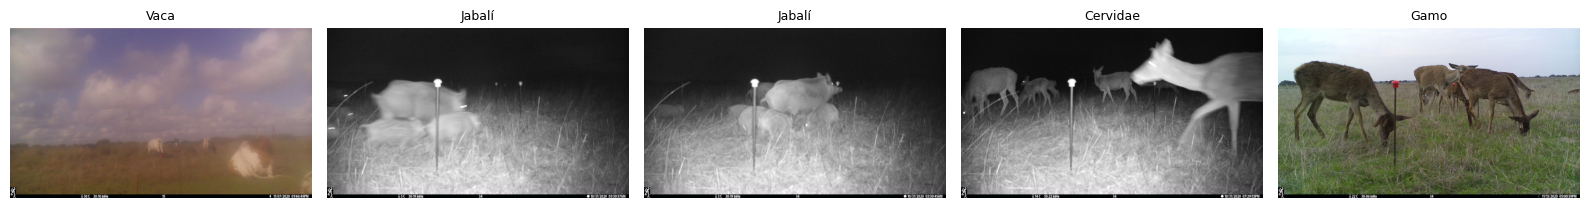

In [24]:
import glob, os, pandas as pd, matplotlib.pyplot as plt, matplotlib.patches as patches
from pathlib import Path
from PIL import Image

# ---------- Configuración ----------
BASE = "/content"
FILAS, COLS, SEED = 1, 5, 0
SOLO_ESPECIE = None        # p. ej. "Jabalí" (usa el nombre en español); None = todas
OCULTAR_UNKNOWN = True     # True = solo fotos con especie real (sin desconocidas/vacías)
DIBUJAR_CAJAS = True
# -----------------------------------

# Diccionario latín -> nombre común (amplíalo con lo que imprima "Sin traducir")
NOMBRES = {
    "sus scrofa": "Jabalí", "meles meles": "Tejón", "lynx pardinus": "Lince ibérico",
    "oryctolagus cuniculus": "Conejo", "cervus elaphus": "Ciervo", "dama dama": "Gamo",
    "vulpes vulpes": "Zorro", "herpestes ichneumon": "Meloncillo", "genetta genetta": "Gineta",
    "lepus granatensis": "Liebre ibérica", "felis catus": "Gato doméstico",
    "felis silvestris": "Gato montés", "canis lupus familiaris": "Perro", "canis lupus": "Lobo",
    "bos taurus": "Vaca", "equus caballus": "Caballo", "equus asinus": "Burro",
    "capra hircus": "Cabra doméstica", "ovis aries": "Oveja", "capreolus capreolus": "Corzo",
    "capra pyrenaica": "Cabra montés", "martes foina": "Garduña", "mustela putorius": "Turón",
    "lutra lutra": "Nutria", "erinaceus europaeus": "Erizo europeo", "sciurus vulgaris": "Ardilla roja",
    "homo sapiens": "Persona", "ave": "Ave", "aves": "Ave",
    # tipos de observación de Camtrap DP
    "animal": "Animal (sin especie)", "human": "Persona", "vehicle": "Vehículo",
    "blank": "Vacía", "empty": "Vacía", "unknown": "Desconocido", "unclassified": "Sin clasificar",
    "sin etiqueta": "Sin etiqueta",
}
GENEROS = {"equus": "Équido", "cervus": "Ciervo", "felis": "Felino", "canis": "Cánido", "bos": "Vaca",
           "erinaceus": "Erizo", "lepus": "Liebre", "capra": "Cabra", "mustela": "Mustélido",
           "martes": "Mustélido", "rattus": "Rata", "mus": "Ratón"}
sin_traducir = set()

def traducir(latin):
    k = str(latin).strip().lower()
    for suf in (" sp.", " spp.", " sp", " spp"):
        if k.endswith(suf):
            k = k[: -len(suf)]
    if k in NOMBRES:
        return NOMBRES[k]
    g = k.split()[0] if k else k
    if g in GENEROS:
        return GENEROS[g]
    sin_traducir.add(str(latin))
    return str(latin)

root = Path(glob.glob(f"{BASE}/**/media.csv", recursive=True)[0]).parent
media = pd.read_csv(root / "media.csv")
obs = pd.read_csv(root / "observations.csv")
obs = obs[obs['count'] > 5]
print(obs.shape)
# Índice de imágenes: nombre de archivo -> ruta completa
idx = {}
for dp, _, files in os.walk(BASE):
    for f in files:
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            idx.setdefault(f, os.path.join(dp, f))
print(f"Imágenes encontradas en disco: {len(idx)}")

# Etiqueta por observación: especie; si falta, tipo de observación
obs["_raw"] = obs["scientificName"].fillna(obs["observationType"]).fillna("sin etiqueta").astype(str)
obs["_es"] = obs["_raw"].map(traducir)

con_media = obs.dropna(subset=["mediaID"])
media["label_raw"] = media["mediaID"].map(con_media.groupby("mediaID")["_raw"].agg(lambda s: ", ".join(sorted(set(s))))).fillna("sin etiqueta")
media["label"] = media["mediaID"].map(con_media.groupby("mediaID")["_es"].agg(lambda s: ", ".join(sorted(set(s))))).fillna("Sin etiqueta")

if sin_traducir:
    print("Sin traducir (se muestran en latín, añádelos a NOMBRES):", sorted(sin_traducir))

cajas = obs.dropna(subset=["mediaID", "bboxX"]).groupby("mediaID") if "bboxX" in obs else None
print(f"Observaciones con caja: {obs['bboxX'].notna().sum() if 'bboxX' in obs else 0}")

pool = media.copy()
if OCULTAR_UNKNOWN:
    pool = pool[~pool["label_raw"].str.lower().str.contains("unknown|blank|empty|unclassified|sin etiqueta")]
if SOLO_ESPECIE:
    pool = pool[pool["label"].str.contains(SOLO_ESPECIE, case=False, na=False)]
pool = pool[pool["filePath"].map(lambda f: Path(str(f)).name in idx)]
print(f"Fotos disponibles con imagen en disco: {len(pool)}")

muestra = pool.sample(n=min(FILAS * COLS, len(pool)), random_state=SEED)
fig, axes = plt.subplots(FILAS, COLS, figsize=(3.2 * COLS, 3.2 * FILAS))
for ax in axes.ravel():
    ax.axis("off")
for ax, (_, r) in zip(axes.ravel(), muestra.iterrows()):
    img = Image.open(idx[Path(str(r["filePath"])).name]).convert("RGB")
    ax.imshow(img)
    if DIBUJAR_CAJAS and cajas is not None and r["mediaID"] in cajas.groups:
        W, H = img.size
        for _, b in cajas.get_group(r["mediaID"]).iterrows():
            ax.add_patch(patches.Rectangle((b.bboxX * W, b.bboxY * H), b.bboxWidth * W, b.bboxHeight * H,
                                           fill=False, edgecolor="lime", linewidth=2))
    ax.set_title(r["label"], fontsize=9, wrap=True)
plt.tight_layout()
plt.show()